# Lab: k-NN em vinhos e dígitos manuscritos

Notebook de aula da página *k-Vizinhos Mais Próximos*: https://insper.github.io/ML/pt/2026.2/classes/knn/

Dois conjuntos de dados que vêm com o scikit-learn. A **parte fundamental** (passos 1–5) usa o conjunto **wine** (178 vinhos, 13 medidas químicas, 3 cultivares) para abrir o k-NN por dentro: ver as unidades decidirem a distância, olhar os vizinhos de um vinho votarem, reescrever o método em quatro linhas de NumPy e escolher $k$ numa divisão de validação. A **parte avançada** (passos 6–8) passa para **dígitos manuscritos** (imagens 8×8, 64 atributos de pixel), em que dá para ver os vizinhos, literalmente, e descobrir o que a distância entende por "parecido" e o que ela não entende.

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar os vinhos e olhar as unidades

**Preveja.** Numa distância euclidiana entre dois vinhos, qual destes quatro atributos vai pesar mais: teor alcoólico, tonalidade (`hue`), magnésio ou prolina? Por quê?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X, y = wine.data, wine.target        # 13 medidas químicas; 3 cultivares (0, 1, 2)
print(X.shape)
print(y.value_counts().sort_index().to_dict())
print(X[['alcohol', 'hue', 'magnesium', 'proline']].agg(['min', 'max', 'std']).round(2))

(178, 13)
{0: 59, 1: 71, 2: 48}
     alcohol   hue  magnesium  proline
min    11.03  0.48      70.00   278.00
max    14.83  1.71     162.00  1680.00
std     0.81  0.23      14.28   314.91


**Resposta.** A prolina: vai de 278 a 1.680 (desvio-padrão 314,9), contra 14,3 do magnésio, 0,81 do teor alcoólico e 0,23 da tonalidade. Na distância euclidiana as diferenças entram em unidades brutas, então a prolina domina a soma só por estar numa escala maior.

## Passo 2 — dividir em treino, validação e teste

**Preveja.** Para que serve cada uma das três partes? Qual delas o k-NN vai guardar dentro de si no `fit`?

In [2]:
from sklearn.model_selection import train_test_split

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25,
                                                  stratify=y_tmp, random_state=42)
print(len(X_train), len(X_val), len(X_test))

106 36 36


**Resposta.** O treino (106 vinhos) é o que o k-NN guarda no `fit`; a validação (36) serve para comparar modelos e escolher $k$; o teste (36) é usado uma vez, no fim, para estimar o desempenho em vinhos novos.

## Passo 3 — baseline e o preço de pular o escalonador

**Preveja.** O mesmo 5-NN, com e sem o `StandardScaler`: qual acerta mais na validação? A diferença vai ser de um ou dois vinhos ou bem maior?

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    'baseline (majoritária)': DummyClassifier(strategy='most_frequent'),
    'k-NN, atributos brutos': KNeighborsClassifier(n_neighbors=5),
    'k-NN, padronizado':      make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name:23s} acurácia de validação {model.score(X_val, y_val):.3f}")

baseline (majoritária)  acurácia de validação 0.389
k-NN, atributos brutos  acurácia de validação 0.694
k-NN, padronizado       acurácia de validação 0.972


**Resposta.** O padronizado, e por muito: 0,972 contra 0,694 na validação, ou seja, 1 erro contra 11 em 36 vinhos (a baseline fica em 0,389). Sem escalonador, a distância é praticamente só a prolina.

**Simulação: a unidade da prolina.** A prolina está em mg/L. Reescreva-a em g/L (divida a coluna por 1.000, no treino e na validação) e rode de novo o 5-NN bruto e o padronizado. São os mesmos vinhos, com a mesma informação. O que muda em cada modelo? Qual coluna passa a mandar na distância bruta?

In [4]:
X_train_g, X_val_g = X_train.copy(), X_val.copy()
X_train_g['proline'] /= 1000                         # mg/L -> g/L
X_val_g['proline'] /= 1000
for unit, (A, B) in {'mg/L': (X_train, X_val), 'g/L': (X_train_g, X_val_g)}.items():
    raw = KNeighborsClassifier(n_neighbors=5).fit(A, y_train).score(B, y_val)
    std = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(A, y_train).score(B, y_val)
    print(f"prolina em {unit:4s}: bruto {raw:.3f} · padronizado {std:.3f}"
          f" · maior desvio-padrão: {A.std().idxmax()} ({A.std().max():.1f})")

prolina em mg/L: bruto 0.694 · padronizado 0.972 · maior desvio-padrão: proline (311.6)
prolina em g/L : bruto 0.861 · padronizado 0.972 · maior desvio-padrão: magnesium (15.3)


**Leitura.** Só mudou a unidade, mas o 5-NN bruto passou de 0,694 para 0,861 na validação, porque a coluna que manda na distância deixou de ser a prolina (desvio-padrão 311,6 no treino) e passou a ser o magnésio (15,3). O padronizado fica em 0,972 nos dois casos: o `StandardScaler` divide cada coluna pelo seu desvio-padrão e cancela a unidade. Um modelo cuja resposta depende da unidade em que uma coluna foi anotada não está medindo semelhança entre vinhos.

## Passo 4 — o k-NN por dentro: os vizinhos votam

**Preveja.** O `fit` da regressão logística aprendia um peso por atributo. O que o `fit` do k-NN guarda? Se os 5 vizinhos de um vinho são dos cultivares 0, 1, 0, 1, 0, o que o `predict_proba` devolve?

In [5]:
knn5 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
print(f"o fit guardou {knn5[-1].n_samples_fit_} linhas de {knn5[-1].n_features_in_} atributos")

wine_id = 123                                        # um vinho da validação
query = X_val.loc[[wine_id]]
dist, idx = knn5[-1].kneighbors(knn5[0].transform(query))
print(pd.DataFrame({'vizinho': X_train.index[idx[0]], 'distância': dist[0].round(2),
                    'cultivar': y_train.iloc[idx[0]].to_numpy()}).to_string(index=False))
print("votos por cultivar:", np.bincount(y_train.iloc[idx[0]], minlength=3))
print("predict_proba:", knn5.predict_proba(query)[0], "· predict:", knn5.predict(query)[0],
      "· verdade:", y_val[wine_id])

o fit guardou 106 linhas de 13 atributos
 vizinho  distância  cultivar
      43       2.86         0
     124       3.03         1
      41       3.32         0
     122       3.73         1
      21       3.78         0
votos por cultivar: [3 2 0]
predict_proba: [0.6 0.4 0. ] · predict: 0 · verdade: 1


**Resposta.** O `fit` não aprende pesos: guarda as 106 linhas de treino (13 atributos) com seus rótulos. Com vizinhos 0, 1, 0, 1, 0, o `predict_proba` devolve as frações de votos, [0,6, 0,4, 0], que é exatamente o caso do vinho 123; como ele é do cultivar 1, o 5-NN erra.

O método inteiro cabe em quatro linhas de NumPy: distâncias, ordenar, pegar os $k$ primeiros, votar.

In [6]:
Z_train, Z_val = knn5[0].transform(X_train), knn5[0].transform(X_val)
D = np.sqrt(((Z_val[:, None, :] - Z_train[None, :, :]) ** 2).sum(axis=2))   # distância de cada vinho
nearest = np.argsort(D, axis=1)[:, :5]                                      # de validação a cada vinho
votes = y_train.to_numpy()[nearest]                                         # de treino
mine = np.array([np.bincount(v, minlength=3).argmax() for v in votes])
print(D.shape, "· igual ao scikit-learn:", (mine == knn5.predict(X_val)).all())

(36, 106) · igual ao scikit-learn: True


**Simulação: o voto muda com $k$.** Para o vinho 123, peça os 15 vizinhos mais próximos de uma vez e, para $k$ = 1, 3, 5, 7, 9, 11, 13 e 15, conte os votos dos $k$ primeiros e imprima a previsão. Com que $k$ a previsão fica certa?

In [7]:
dist, idx = knn5[-1].kneighbors(knn5[0].transform(query), n_neighbors=15)
labels = y_train.iloc[idx[0]].to_numpy()
print("cultivares dos 15 vizinhos, do mais próximo:", labels, "· verdade:", y_val[wine_id])
for k in range(1, 16, 2):
    v = np.bincount(labels[:k], minlength=3)
    print(f"k = {k:2d}: votos {v} -> previsão {v.argmax()}")

cultivares dos 15 vizinhos, do mais próximo: [0 1 0 1 0 1 1 1 1 1 1 1 0 1 1] · verdade: 1
k =  1: votos [1 0 0] -> previsão 0
k =  3: votos [2 1 0] -> previsão 0
k =  5: votos [3 2 0] -> previsão 0
k =  7: votos [3 4 0] -> previsão 1
k =  9: votos [3 6 0] -> previsão 1
k = 11: votos [3 8 0] -> previsão 1
k = 13: votos [4 9 0] -> previsão 1
k = 15: votos [ 4 11  0] -> previsão 1


**Leitura.** Os rótulos dos 15 vizinhos, do mais próximo, são 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1. Com $k$ = 1, 3 e 5 a maioria é o cultivar 0 (errado); a partir de $k = 7$ (4 votos contra 3) a previsão vira 1 e acerta, chegando a 11 contra 4 com $k = 15$. Os poucos vizinhos mais próximos são uma amostra pequena e ruidosa da vizinhança; perto da fronteira, mais votos dão uma resposta mais estável.

## Passo 5 — escolher $k$ na validação e testar uma vez

**Preveja.** Com $k = 1$, quanto dá a acurácia de *treino*? Esse número diz algo sobre vinhos novos?

In [8]:
rows = []
for k in range(1, 32, 2):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train, y_train)
    val_acc = model.score(X_val, y_val)
    rows.append({'k': k, 'treino': model.score(X_train, y_train), 'validação': val_acc,
                 'erros val': round((1 - val_acc) * len(y_val))})
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))
best_k = int(table.loc[table['validação'].idxmax(), 'k'])   # primeiro (menor) k com o melhor escore

final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final.fit(X_tmp, y_tmp)                                      # treino + validação, mesma receita
print(f"k escolhido: {best_k} · acurácia de teste {final.score(X_test, y_test):.3f} em {len(y_test)} vinhos")

 k  treino  validação  erros val
 1   1.000      0.944          2
 3   0.972      0.972          1
 5   0.972      0.972          1
 7   0.953      1.000          0
 9   0.962      1.000          0
11   0.962      1.000          0
13   0.972      1.000          0
15   0.962      1.000          0
17   0.962      1.000          0
19   0.972      1.000          0
21   0.972      1.000          0
23   0.972      1.000          0
25   0.972      1.000          0
27   0.972      1.000          0
29   0.962      1.000          0
31   0.962      1.000          0


k escolhido: 7 · acurácia de teste 1.000 em 36 vinhos


**Resposta.** Com $k = 1$ a acurácia de treino é 1,000, porque cada vinho de treino é o seu próprio vizinho mais próximo (distância 0); isso não diz nada sobre vinhos novos, e na validação o 1-NN erra 2 (0,944). A validação escolheu $k = 7$ (o menor com 0 erros), e o modelo final, reajustado em treino + validação, acertou os 36 vinhos de teste (1,000).

## Passo 6 — dígitos: um conjunto em que os pixels são os atributos

**Preveja.** Numa imagem 8×8, os 64 pixels já estão na mesma unidade (tinta, de 0 a 16). Padronizar vai ajudar, atrapalhar ou não mudar nada? E quais dígitos você espera que o k-NN confunda?

In [9]:
from sklearn.datasets import load_digits

digits = load_digits()
Xd, yd = digits.data, digits.target          # 1797 imagens de 8x8 pixels, cada pixel de 0 a 16
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.25,
                                                        stratify=yd, random_state=0)
print(Xd.shape, len(Xd_train), len(Xd_test))

knn_d = KNeighborsClassifier(n_neighbors=3).fit(Xd_train, yd_train)
pred = knn_d.predict(Xd_test)
scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(Xd_train, yd_train)
print(f"baseline             {DummyClassifier().fit(Xd_train, yd_train).score(Xd_test, yd_test):.3f}")
print(f"3-NN, pixels brutos  {(pred == yd_test).mean():.3f}")
print(f"3-NN, padronizado    {scaled.score(Xd_test, yd_test):.3f}")

wrong = np.flatnonzero(pred != yd_test)
print(f"{len(wrong)} de {len(yd_test)} dígitos de teste errados")
print(pd.crosstab(pd.Series(yd_test, name='verdadeiro'), pd.Series(pred, name='previsto')))

(1797, 64) 1347 450
baseline             0.102
3-NN, pixels brutos  0.987


3-NN, padronizado    0.982
6 de 450 dígitos de teste errados


previsto     0   1   2   3   4   5   6   7   8   9
verdadeiro                                        
0           45   0   0   0   0   0   0   0   0   0
1            0  46   0   0   0   0   0   0   0   0
2            0   0  44   0   0   0   0   0   0   0
3            0   0   0  45   0   0   0   1   0   0
4            0   0   0   0  44   0   0   0   0   1
5            0   0   0   0   0  46   0   0   0   0
6            0   0   0   0   0   0  45   0   0   0
7            0   0   0   0   0   0   0  45   0   0
8            0   1   0   1   0   0   0   0  41   0
9            0   0   0   2   0   0   0   0   0  43


**Resposta.** Padronizar não ajuda: os pixels já estão na mesma unidade, e o 3-NN cai de 0,987 para 0,982, provavelmente porque o escalonador amplia pixels de borda quase sempre vazios, cuja pouca variação é ruído. Os erros são poucos (6 de 450) e ficam entre dígitos de traço parecido: 9 lido como 3 (duas vezes), 8 lido como 1 e como 3, 3 lido como 7 e 4 lido como 9.

## Passo 7 — olhar os vizinhos

**Preveja.** Para um 9 que o modelo leu como 3, que imagens você espera encontrar entre os seus 5 vizinhos mais próximos?

teste #0: verdadeiro 2, previsto 2 · vizinhos [2 2 2 2 2] a distâncias [20.3 20.6 20.7 24.  25.1]
teste #32: verdadeiro 9, previsto 3 · vizinhos [3 3 3 9 9] a distâncias [21.9 26.5 27.8 28.2 29.4]


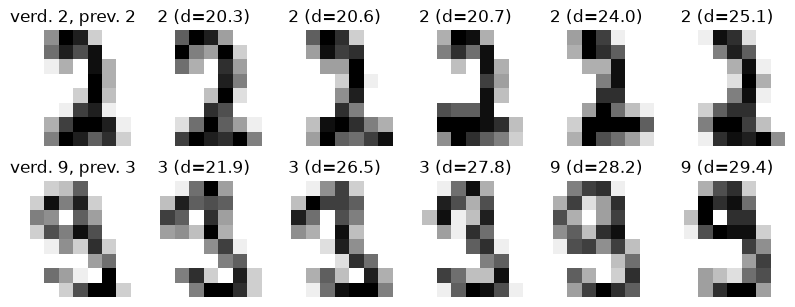

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(8, 3.3))
for row, i in zip(axes, [0, wrong[0]]):                     # um certo, um errado
    dist, idx = knn_d.kneighbors(Xd_test[[i]], n_neighbors=5)
    print(f"teste #{i}: verdadeiro {yd_test[i]}, previsto {pred[i]} · vizinhos {yd_train[idx[0]]} "
          f"a distâncias {dist[0].round(1)}")
    row[0].imshow(Xd_test[i].reshape(8, 8), cmap='gray_r')
    row[0].set_title(f"verd. {yd_test[i]}, prev. {pred[i]}")
    for ax, j, d in zip(row[1:], idx[0], dist[0]):
        ax.imshow(Xd_train[j].reshape(8, 8), cmap='gray_r')
        ax.set_title(f"{yd_train[j]} (d={d:.1f})")
    for ax in row:
        ax.axis('off')
plt.tight_layout()
plt.show()

**Resposta.** Esperaria 3s e 9s de traço parecido, e é isso: os 5 vizinhos do 9 do teste #32 são [3 3 3 9 9], com os três 3 (distâncias 21,9 a 27,8) mais próximos que os dois 9 (28,2 e 29,4). Pela distância pixel a pixel, aquele 9 se parece mais com esses 3 do que com os 9 do treino.

**Simulação: deslocar um dígito um pixel.** Pegue o 2 de teste #0 e desloque a imagem uma coluna para a direita (a coluna que entra fica em branco). A que distância a imagem deslocada fica da original? Compare com a distância dos vizinhos acima (20,3). O que o 3-NN prevê para ela? Depois desloque *todas* as imagens de teste 1 e 2 pixels, para os dois lados, e meça a acurácia.

In [11]:
def shift(images, dx):
    """Desloca imagens 8x8 achatadas dx colunas (positivo: direita); a coluna que entra fica em branco."""
    img = images.reshape(-1, 8, 8)
    out = np.zeros_like(img)
    if dx > 0:
        out[:, :, dx:] = img[:, :, :-dx]
    elif dx < 0:
        out[:, :, :dx] = img[:, :, -dx:]
    else:
        out[:] = img
    return out.reshape(len(images), 64)


moved = shift(Xd_test[[0]], 1)
dist, idx = knn_d.kneighbors(moved)
print(f"distância até o original: {np.linalg.norm(moved - Xd_test[[0]]):.1f}")
print(f"3-NN prevê {knn_d.predict(moved)[0]} · vizinhos {yd_train[idx[0]]} a distâncias {dist[0].round(1)}")
for dx in [-2, -1, 0, 1, 2]:
    print(f"deslocamento {dx:+d}: acurácia {knn_d.score(shift(Xd_test, dx), yd_test):.3f}")

distância até o original: 50.7
3-NN prevê 0 · vizinhos [9 0 0] a distâncias [50.4 50.4 50.4]
deslocamento -2: acurácia 0.162
deslocamento -1: acurácia 0.598
deslocamento +0: acurácia 0.987
deslocamento +1: acurácia 0.604
deslocamento +2: acurácia 0.133


**Leitura.** Deslocado de um pixel, o 2 fica a 50,7 da própria imagem original, bem mais longe que os seus vizinhos de verdade (20,3): para a distância pixel a pixel, virou outra imagem. Seus 3 vizinhos ficam todos a 50,4 ([9 0 0]) e o 3-NN prevê 0. Deslocando todo o teste, a acurácia cai de 0,987 para cerca de 0,60 com um pixel (0,598 e 0,604) e para 0,16 e 0,13 com dois: a distância não sabe que um dígito movido continua sendo o mesmo dígito.

## Passo 8 — acrescentar atributos de ruído

**Preveja.** Acrescente às 64 colunas reais colunas de ruído puro, na mesma faixa de 0 a 16. Com 64 colunas de ruído (tantas quanto as reais), a acurácia cai muito ou pouco? E com 1.024?

In [12]:
rng = np.random.default_rng(0)
for n_noise in [0, 64, 256, 1024]:
    noise = rng.uniform(0, 16, size=(len(Xd), n_noise))      # "pixels" falsos, na mesma faixa dos reais
    Xn = np.hstack([Xd, noise])
    a, b, c, d = train_test_split(Xn, yd, test_size=0.25, stratify=yd, random_state=0)
    acc = KNeighborsClassifier(n_neighbors=3).fit(a, c).score(b, d)
    print(f"{n_noise:5d} colunas de ruído ({Xn.shape[1]:4d} no total): acurácia {acc:.3f}")

    0 colunas de ruído (  64 no total): acurácia 0.987
   64 colunas de ruído ( 128 no total): acurácia 0.960
  256 colunas de ruído ( 320 no total): acurácia 0.842
 1024 colunas de ruído (1088 no total): acurácia 0.582


**Resposta.** Com 64 colunas de ruído a acurácia cai pouco (de 0,987 para 0,960); com 256 cai para 0,842 e com 1.024 desaba para 0,582. Cada coluna de ruído soma à distância tanto quanto um pixel real, e com muitas delas a diferença entre os dígitos se afoga.

**Simulação: o tamanho do ruído.** Mantenha 1.024 colunas de ruído, mas sorteie-as em faixas menores: de 0 a 16, de 0 a 4 e de 0 a 1. Para cada faixa, meça a acurácia do 3-NN sem escalonamento e com `StandardScaler` num pipeline. O que prejudica o k-NN: o número de colunas de ruído ou quanto elas somam à distância?

In [13]:
rng = np.random.default_rng(0)
for high in [16, 4, 1]:
    noise = rng.uniform(0, high, size=(len(Xd), 1024))
    a, b, c, d = train_test_split(np.hstack([Xd, noise]), yd, test_size=0.25, stratify=yd, random_state=0)
    raw = KNeighborsClassifier(n_neighbors=3).fit(a, c).score(b, d)
    std = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(a, c).score(b, d)
    print(f"ruído de 0 a {high:2d}: sem escalonamento {raw:.3f} · com StandardScaler {std:.3f}")

ruído de 0 a 16: sem escalonamento 0.549 · com StandardScaler 0.440


ruído de 0 a  4: sem escalonamento 0.982 · com StandardScaler 0.478


ruído de 0 a  1: sem escalonamento 0.984 · com StandardScaler 0.464


**Leitura.** Sem escalonamento, as mesmas 1.024 colunas derrubam a acurácia para 0,549 quando vão de 0 a 16, mas quase não atrapalham quando vão de 0 a 4 (0,982) ou de 0 a 1 (0,984, contra 0,987 sem ruído). O que prejudica é quanto o ruído soma à distância, não o número de colunas. Com `StandardScaler`, todas as faixas caem para 0,44 a 0,48: padronizar dá a cada coluna de ruído o mesmo peso de um pixel real, e o escalonador não sabe separar atributos úteis de inúteis.

**Responda.** Em uma frase cada:

1. o que o `fit` do k-NN guarda e em que momento acontece o trabalho de verdade?
2. Por que o k-NN sem escalonamento mudou de resposta quando a prolina mudou de unidade?
3. Por que um 2 deslocado de um pixel foi lido como 0?

**Resposta.**

1. O `fit` só guarda as linhas de treino e seus rótulos; o trabalho de verdade (distâncias a todas elas, ordenar e votar) acontece no `predict`.
2. Porque sem escalonamento a distância é dominada pela coluna de maior escala, e passar a prolina de mg/L para g/L trocou essa coluna (da prolina para o magnésio), mudando quem são os vizinhos.
3. Porque a distância compara pixel a pixel: o 2 deslocado fica a 50,7 do original e longe de todos os 2 do treino, e as imagens que por acaso ficam mais perto dele (a 50,4) são de outros dígitos, com maioria de 0.

## Sua vez

Para casa, com mais tempo:

1. **Pesos.** Repita o passo 5 com `KNeighborsClassifier(n_neighbors=k, weights='distance')`. A acurácia de treino fica em 1,000 para todo $k$? Por quê? (Dica: qual é o peso de um vizinho a distância 0?)
2. **Escolher $k$ para os dígitos.** O passo 6 usou $k = 3$ sem justificativa. Separe uma divisão de validação de dentro de `Xd_train`, avalie $k$ ímpar de 1 a 15 com `metric='euclidean'` e com `metric='manhattan'`, escolha o melhor par e só então meça o teste, uma vez.
3. **Ensinar o deslocamento.** Acrescente ao treino cópias de cada imagem deslocadas um pixel para a esquerda e para a direita (use a função `shift` da simulação do passo 7; os rótulos se repetem). Refaça a medida de acurácia nas imagens de teste deslocadas. Quanto volta? Quanto custa, em linhas guardadas e em distâncias por previsão?
4. **Resgate com PCA.** Na versão com 1.024 colunas de ruído de 0 a 16, coloque `PCA(n_components=30)` antes do k-NN num pipeline. Quanto da acurácia perdida volta? Por que a PCA conseguiria separar os pixels reais do ruído aqui? ([Redução de Dimensionalidade](https://insper.github.io/ML/pt/2026.2/classes/dimensionality-reduction/))
5. **Regressão.** Com `load_diabetes(return_X_y=True)`, compare o `KNeighborsRegressor` (escalonado, $k$ escolhido numa divisão de validação) com a `LinearRegression` num hold-out, usando $R^2$. Qual vence? Isso bate com o que a seção da maldição da dimensionalidade preveria com 10 atributos e 442 linhas?

### Sua vez — exercício 1: pesos pela distância

In [14]:
rows = []
for k in range(1, 32, 2):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights='distance'))
    model.fit(X_train, y_train)
    val_acc = model.score(X_val, y_val)
    rows.append({'k': k, 'treino': model.score(X_train, y_train), 'validação': val_acc,
                 'erros val': round((1 - val_acc) * len(y_val))})
table_w = pd.DataFrame(rows)
print(table_w.round(3).to_string(index=False))

 k  treino  validação  erros val
 1     1.0      0.944          2
 3     1.0      0.972          1
 5     1.0      0.972          1
 7     1.0      1.000          0
 9     1.0      1.000          0
11     1.0      1.000          0
13     1.0      1.000          0
15     1.0      1.000          0
17     1.0      1.000          0
19     1.0      1.000          0
21     1.0      1.000          0
23     1.0      1.000          0
25     1.0      1.000          0
27     1.0      1.000          0
29     1.0      1.000          0
31     1.0      1.000          0


**Conclusão.** Sim: com `weights='distance'` a acurácia de treino é 1,000 para todo $k$. Cada vinho de treino é vizinho de si mesmo a distância 0, cujo peso $1/d$ é infinito (o scikit-learn dá todo o voto aos vizinhos a distância zero), então ele sempre vota no próprio rótulo. A validação fica igual à dos pesos uniformes (0,944 com $k = 1$, 0,972 com 3 e 5, 1,000 a partir de 7), o que mostra que essa acurácia de treino não informa nada.

### Sua vez — exercício 2: escolher $k$ para os dígitos

In [15]:
Xd_fit, Xd_val, yd_fit, yd_val = train_test_split(Xd_train, yd_train, test_size=0.25,
                                                  stratify=yd_train, random_state=42)
rows = []
for metric in ['euclidean', 'manhattan']:
    for k in range(1, 16, 2):
        acc = KNeighborsClassifier(n_neighbors=k, metric=metric).fit(Xd_fit, yd_fit).score(Xd_val, yd_val)
        rows.append({'k': k, 'métrica': metric, 'validação': acc})
grid = pd.DataFrame(rows).pivot(index='k', columns='métrica', values='validação')
print(grid.round(3))
best = pd.DataFrame(rows).sort_values('validação', ascending=False, kind='stable').iloc[0]
best_kd, best_metric = int(best['k']), best['métrica']

final_d = KNeighborsClassifier(n_neighbors=best_kd, metric=best_metric).fit(Xd_train, yd_train)
print(f"escolhido: k = {best_kd}, {best_metric} (validação {best['validação']:.3f})"
      f" · acurácia de teste {final_d.score(Xd_test, yd_test):.3f}")

métrica  euclidean  manhattan
k                            
1            0.979      0.976
3            0.982      0.973
5            0.982      0.970
7            0.979      0.973
9            0.976      0.967
11           0.970      0.967
13           0.961      0.961
15           0.961      0.961
escolhido: k = 3, euclidean (validação 0.982) · acurácia de teste 0.987


**Conclusão.** Na validação (337 imagens separadas de `Xd_train`), a euclidiana vence ou empata com a Manhattan em todo $k$, e o melhor par é $k = 3$ com a euclidiana (0,982, empatado com $k = 5$; fica o menor). Medido uma vez, o teste dá 0,987: o mesmo $k = 3$ que o passo 6 usou sem justificativa, agora escolhido na validação.

### Sua vez — exercício 3: ensinar o deslocamento

In [16]:
Xd_aug = np.vstack([Xd_train, shift(Xd_train, -1), shift(Xd_train, 1)])
yd_aug = np.concatenate([yd_train] * 3)
knn_aug = KNeighborsClassifier(n_neighbors=3).fit(Xd_aug, yd_aug)
print(f"linhas guardadas: {len(Xd_train)} -> {knn_aug.n_samples_fit_}"
      f" (distâncias por previsão: {len(Xd_train)} -> {len(Xd_aug)})")
for dx in [-2, -1, 0, 1, 2]:
    test_dx = shift(Xd_test, dx)
    print(f"deslocamento {dx:+d}: original {knn_d.score(test_dx, yd_test):.3f}"
          f" · treino aumentado {knn_aug.score(test_dx, yd_test):.3f}")

linhas guardadas: 1347 -> 4041 (distâncias por previsão: 1347 -> 4041)
deslocamento -2: original 0.162 · treino aumentado 0.596


deslocamento -1: original 0.598 · treino aumentado 0.984


deslocamento +0: original 0.987 · treino aumentado 0.984
deslocamento +1: original 0.604 · treino aumentado 0.987


deslocamento +2: original 0.133 · treino aumentado 0.596


**Conclusão.** Com as cópias deslocadas no treino, a acurácia nas imagens de teste deslocadas de um pixel volta de cerca de 0,60 para 0,984 (esquerda) e 0,987 (direita), praticamente a original; nas deslocadas de dois pixels sobe de 0,16 e 0,13 para 0,596, o patamar que antes era o de um pixel. Sem deslocamento fica em 0,984 (contra 0,987). O custo: o modelo guarda o triplo de linhas (1.347 para 4.041) e cada previsão calcula o triplo de distâncias; o k-NN só reconhece as variações que já viu no treino.

### Sua vez — exercício 4: resgate com PCA

In [17]:
from sklearn.decomposition import PCA

rng = np.random.default_rng(42)
Xn = np.hstack([Xd, rng.uniform(0, 16, size=(len(Xd), 1024))])
a, b, c, d = train_test_split(Xn, yd, test_size=0.25, stratify=yd, random_state=0)
knn_noise = KNeighborsClassifier(n_neighbors=3).fit(a, c)
knn_pca = make_pipeline(PCA(n_components=30, random_state=42), KNeighborsClassifier(n_neighbors=3)).fit(a, c)
print(f"sem ruído {knn_d.score(Xd_test, yd_test):.3f} · com ruído {knn_noise.score(b, d):.3f}"
      f" · com ruído + PCA(30) {knn_pca.score(b, d):.3f}")

pca = knn_pca[0]
real_share = (pca.components_[:, :64] ** 2).sum(axis=1)   # cada componente tem norma 1
print("variância explicada das 10 primeiras componentes:", pca.explained_variance_[:10].round(1))
print(f"variância de uma coluna de ruído: {16 ** 2 / 12:.1f}")
print("peso dos 64 pixels reais em cada componente:", real_share.round(2))

sem ruído 0.987 · com ruído 0.564 · com ruído + PCA(30) 0.791
variância explicada das 10 primeiras componentes: [196.7 180.8 163.4 119.   92.4  83.4  79.1  74.4  72.9  71.9]
variância de uma coluna de ruído: 21.3
peso dos 64 pixels reais em cada componente: [0.9  0.89 0.86 0.78 0.63 0.51 0.4  0.15 0.05 0.06 0.05 0.07 0.04 0.04
 0.06 0.03 0.04 0.06 0.07 0.04 0.02 0.03 0.05 0.02 0.03 0.04 0.02 0.03
 0.02 0.02]


**Conclusão.** Com 1.024 colunas de ruído de 0 a 16 a acurácia cai de 0,987 para 0,564; com `PCA(n_components=30)` antes do 3-NN ela volta para 0,791, recuperando pouco mais da metade da perda. A PCA consegue porque os pixels reais são correlacionados e concentram variância em poucas direções (196,7, 180,8, 163,4, ...), enquanto o ruído é independente e espalha a sua (21,3 por coluna) por todas as direções. A recuperação é parcial porque, com 1.024 colunas de ruído e 1.347 linhas, as maiores direções do ruído chegam por acaso a cerca de 70: só as ~7 primeiras componentes são dominadas pelos pixels reais (peso de 0,90 a 0,40), e as demais são quase só ruído.

### Sua vez — exercício 5: regressão

In [18]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

Xr, yr = load_diabetes(return_X_y=True)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)
Xr_fit, Xr_val, yr_fit, yr_val = train_test_split(Xr_train, yr_train, test_size=0.25, random_state=42)

val_r2 = {k: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
             .fit(Xr_fit, yr_fit).score(Xr_val, yr_val) for k in range(1, 52, 2)}
best_kr = max(val_r2, key=val_r2.get)
print("R² de validação por k:", {k: round(v, 3) for k, v in val_r2.items() if k in (1, 5, 11, 21, 31, 51)},
      f"· melhor k = {best_kr} ({val_r2[best_kr]:.3f})")

knn_r = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=best_kr)).fit(Xr_train, yr_train)
lin_r = LinearRegression().fit(Xr_train, yr_train)
print(f"{Xr.shape[0]} linhas, {Xr.shape[1]} atributos")
print(f"R² no hold-out: k-NN (k = {best_kr}) {knn_r.score(Xr_test, yr_test):.3f}"
      f" · regressão linear {lin_r.score(Xr_test, yr_test):.3f}")

R² de validação por k: {1: -0.046, 5: 0.41, 11: 0.466, 21: 0.457, 31: 0.426, 51: 0.415} · melhor k = 15 (0.475)
442 linhas, 10 atributos
R² no hold-out: k-NN (k = 15) 0.424 · regressão linear 0.453


**Conclusão.** A regressão linear vence: $R^2$ de 0,453 no hold-out contra 0,424 do k-NN com $k = 15$ (escolhido na validação, onde teve 0,475). Bate com a maldição da dimensionalidade: com 10 atributos e só 442 linhas (353 no treino), a vizinhança de cada paciente é larga e pouco local, e o k-NN acaba fazendo médias grosseiras; a regressão linear, com 11 parâmetros, aproveita melhor poucos dados quando a relação é aproximadamente linear.